# grtrans Thermal Synchrotron Emissivity $j_\nu$

This notebook reproduces the thermal synchrotron emissivity **fitting functions used by grtrans** (Dexter 2016), translated directly from the Fortran source ([`polsynchemis.f90`](polsynchemis.f90), [`calc_maxjutt.f90`](calc_maxjutt.f90)) into pure Python/NumPy. No Fortran compilation is required.

**What this notebook does:**
1. Implements the grtrans emissivity fits for a Maxwell–Jüttner (relativistic thermal) electron distribution:
   - `synchemis` — unpolarized thermal synchrotron (**Mahadevan et al. 1996**)
   - `polsynchth` — polarized thermal synchrotron (**Huang et al. 2009** / **Shcherbakov 2008** transfer)
   - `sympolemisth` — polarized thermal synchrotron (**Pandya et al. 2016** fits)
   - `maxjutt` — multi-Maxwellian decomposition (super-thermal tail, Alwin Mao-style)
2. Computes $j_\nu$ across a frequency grid in units of $\nu_c' = \tfrac{3}{2}\nu_B \sin\theta \, \theta_e^2$
3. Plots spectra for all Stokes parameters (I, Q, U, V) and compares the models
4. Scans the mildly relativistic regime $\theta_e \in [0.1, 10]$

**To use:** Adjust the parameters in the "Adjustable parameters" cell and run all cells. Each routine mirrors the Fortran subroutine of the same name so results can be cross-checked against grtrans itself.

In [16]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

In [17]:
# Set plot parameters for publication-quality figures
plt.rcParams['figure.figsize']  = 12, 8
plt.rcParams['lines.linewidth'] = 1.5
plt.rcParams['font.family']     = 'serif'
plt.rcParams['font.weight']     = 'bold'
plt.rcParams['font.size']       = 14
plt.rcParams['text.usetex']     = True
plt.rcParams['axes.linewidth']  = 1.5
plt.rcParams['axes.titlesize']  = 'large'
plt.rcParams['axes.labelsize']  = 'large'

plt.rcParams['xtick.major.size'] = 8
plt.rcParams['xtick.minor.size'] = 4
plt.rcParams['xtick.major.pad']  = 8
plt.rcParams['xtick.color']      = 'k'
plt.rcParams['xtick.labelsize']  = 'large'
plt.rcParams['xtick.direction']  = 'in'

plt.rcParams['ytick.major.size'] = 8
plt.rcParams['ytick.minor.size'] = 4
plt.rcParams['ytick.major.pad']  = 8
plt.rcParams['ytick.color']      = 'k'
plt.rcParams['ytick.labelsize']  = 'large'
plt.rcParams['ytick.direction']  = 'in'

### Define Physical Constants and Parameters

The emissivity fits take the plasma state in CGS units. The key parameters are:
- `theta_e`: dimensionless electron temperature ($\theta_e = k_B T_e / m_e c^2$)
- `B`: magnetic field strength in Gauss
- `n_e`: electron number density in $\mathrm{cm}^{-3}$
- `theta_B`: angle between $\vec{B}$ and the line of sight in radians

The characteristic frequency used for the x-axis is $\nu_c' = \tfrac{3}{2}\,\nu_B \sin\theta_B\,\theta_e^2$ with $\nu_B = eB/(2\pi m_e c)$.

In [18]:
# Physical constants in CGS (from grtrans phys_constants.f90)
m_e = 9.10938188e-28   # electron mass [g]
c   = 2.99792458e10    # speed of light [cm/s]
q_e = 4.8032e-10       # electron charge [esu]
k_B = 1.38e-16         # Boltzmann constant [erg/K]
h   = 6.626e-27        # Planck constant [erg s]

In [19]:
# Basic functions
def get_nuB(B):
    """Cyclotron (gyro) frequency eB/(2 pi m_e c)"""
    return q_e*B/(2.*np.pi*m_e*c)

def get_nuc(B, gamma, theta_B):
    """Characteristic synchrotron frequency for Lorentz factor gamma"""
    return 1.5*get_nuB(B)*np.sin(theta_B)*gamma*gamma

def get_nuc_prime(B, theta_e, theta_B):
    """Characteristic thermal synchrotron frequency: (3/2) nu_B sin(theta) theta_e^2"""
    return 1.5*get_nuB(B)*np.sin(theta_B)*theta_e*theta_e

def angle(theta): return 180.*theta/np.pi

def normed(arr): return arr/max(arr)

def bnu(T, nu):
    """Planck function B_nu(T) [erg s^-1 cm^-2 Hz^-1 sr^-1].
    Mirrors bnu in polsynchemis.f90: Rayleigh-Jeans limit for h nu / k T < 1e-6."""
    T = np.atleast_1d(float(T))
    nu = np.atleast_1d(nu)
    arg = h*nu/(k_B*T)
    out = np.where(arg < 1e-6,
                   2.*nu**2*k_B*T/c**2,
                   2.*h*nu**3/c**2/np.expm1(np.clip(arg, None, 700.)))
    out = np.where(out == 0., np.finfo(float).tiny, out)
    return out.reshape(-1) if out.size > 1 else float(out)

#### grtrans fitting functions (from `polsynchemis.f90`)

The emissivity fits are written in terms of $x = \nu/\nu_c$ and approximate the thermal synchrotron integral over a Maxwell–Jüttner distribution:

- $I'(x)$ (`ipx`) — Mahadevan et al. (1996) fit used by `synchemis`
- $I(x)$ (`iix`), $I_Q(x)$ (`iqx`), $I_V(x)$ (`ivx`) — Huang et al. (2009) fits used by `polsynchth`

In [20]:
def ipx(x):
    """I'(x), Mahadevan et al. (1996). Used in synchemis."""
    x = np.asarray(x, dtype=float)
    return 4.0505*x**(-1./6.)*(1. + 0.40*x**(-1./4.) + 0.5316*x**(-1./2.)) \
           * np.exp(-1.8899*x**(1./3.))

def iix(x):
    """I(x), Mahadevan et al. (1996) / Huang et al. (2009). Stokes I fit."""
    x = np.asarray(x, dtype=float)
    return 2.5651*(1. + 1.92*x**(-1./3.) + 0.9977*x**(-2./3.)) \
           * np.exp(-1.8899*x**(1./3.))

def iqx(x):
    """I_Q(x), Huang et al. (2009). Stokes Q fit."""
    x = np.asarray(x, dtype=float)
    return 2.5651*(1. + 0.93193*x**(-1./3.) + 0.499873*x**(-2./3.)) \
           * np.exp(-1.8899*x**(1./3.))

def ivx(x):
    """I_V(x), Huang et al. (2009). Stokes V fit."""
    x = np.asarray(x, dtype=float)
    return (1.81384/x + 3.42319*x**(-2./3.) + 0.0292545*x**(-1./2.)
            + 2.03773*x**(-1./3.)) * np.exp(-1.8899*x**(1./3.))

#### Emissivity routines (Python ports of the grtrans Fortran subroutines)

Each routine returns a dict of Stokes emissivities `jI, jQ, jU, jV` and the corresponding Kirchhoff absorption coefficients $\alpha_\nu = j_\nu / B_\nu(T)$, matching the structure of the 11-column coefficient array in grtrans (`K[:,1:4]` emission, `K[:,5:8]` absorption).

- **`synchemis`** — unpolarized, Mahadevan et al. (1996): $j_\nu = 2.215\times10^{-30}\,\nu\, n_e\, I'(x)/\theta_e^2$
- **`polsynchth`** — polarized, Huang et al. (2009) / Shcherbakov (2008)
- **`sympolemisth`** — polarized, Pandya et al. (2016) fits
- **`maxjutt`** — sums weighted Maxwellians at $T_i = T_{\min}\delta^i$ (from `calc_maxjutt.f90`)

In [21]:
def synchemis(nu, n, B, T):
    """Unpolarized thermal synchrotron (Mahadevan et al. 1996).
    Port of subroutine synchemis in polsynchemis.f90."""
    nu = np.asarray(nu, dtype=float)
    theta_e = k_B*T/m_e/c**2
    nuc = 3.*q_e*B/(4.*np.pi*m_e*c)*theta_e**2   # grtrans uses no sin(theta) here
    xm = nu/nuc
    jI = 4.43e-30/2. * nu * n * ipx(xm)/theta_e**2
    aI = jI/bnu(T, nu)
    return {'jI': jI, 'jQ': np.zeros_like(nu), 'jU': np.zeros_like(nu),
            'jV': np.zeros_like(nu), 'aI': aI}

def polsynchth(nu, n, B, T, theta):
    """Polarized thermal synchrotron (Huang et al. 2009; Shcherbakov 2008).
    Port of subroutine polsynchth in polsynchemis.f90 (emission/absorption part)."""
    nu = np.asarray(nu, dtype=float)
    theta_e = k_B*T/m_e/c**2
    nuc = 3.*q_e*B*np.sin(theta)/(4.*np.pi*m_e*c)*theta_e**2
    xm = nu/nuc
    jI = q_e**2/c/np.sqrt(3.)/2. * n/theta_e**2 * nu * iix(xm)
    jQ = q_e**2/c/np.sqrt(3.)/2. * n/theta_e**2 * nu * iqx(xm)
    jV = 4.*q_e**2/c/3./np.sqrt(3.)/np.tan(theta) * n/2./theta_e**3 * nu * ivx(xm)
    Bn = bnu(T, nu)
    return {'jI': jI, 'jQ': jQ, 'jU': np.zeros_like(nu), 'jV': jV,
            'aI': jI/Bn, 'aQ': jQ/Bn, 'aV': jV/Bn}

def sympolemisth(nu, n, B, T, theta):
    """Polarized thermal synchrotron, Pandya et al. (2016) fits.
    Port of subroutine sympolemisth in polsynchemis.f90."""
    nu = np.asarray(nu, dtype=float)
    theta_e = k_B*T/m_e/c**2
    nuc0 = q_e*B/m_e/c/2./np.pi                       # = nu_B
    x = nu/(2./9.*nuc0*theta_e**2*np.sin(theta))
    jis = np.sqrt(2.)*np.pi/27.*np.sin(theta) \
          * (np.sqrt(x) + 2.**(11./12.)*x**(1./6.))**2
    jqs = -np.sqrt(2.)*np.pi/27.*np.sin(theta) \
          * (np.sqrt(x) + (7.*theta_e**(24./25.) + 35.)
             / (10.*theta_e**(24./25.) + 75.)*2.**(11./12.)*x**(1./6.))**2
    jvs = -(37. - 87.*np.sin(theta - 28./25.))/100./(theta_e + 1.) \
          * (1. + (theta_e**(3./5.)/25. + 7./10.)*x**(9./25.))**(5./3.)
    fac = n*q_e**2/c*nuc0*np.exp(-x**(1./3.))
    jI, jQ, jV = fac*jis, -fac*jqs, -fac*jvs
    Bn = bnu(T, nu)
    return {'jI': jI, 'jQ': jQ, 'jU': np.zeros_like(nu), 'jV': jV,
            'aI': jI/Bn, 'aQ': jQ/Bn, 'aV': jV/Bn}

def maxjutt(nu, n, B, T, theta, delta=2.,
            weights=np.array([1., 2., 3., 5., 7., 11., 13., 17.])):
    """Multi-Maxwellian (MAXJUTT) decomposition: sums weighted Maxwellians
    T_i = T_min * delta^i. Port of calc_maxjutt_subroutine in calc_maxjutt.f90."""
    weights = np.asarray(weights, dtype=float)
    w = weights/weights.sum()
    i_arr = np.arange(len(w))
    delta_arr = delta**i_arr
    dwsum = np.sum(w*delta_arr)
    T_min = T/dwsum
    out = {key: np.zeros_like(np.asarray(nu, dtype=float))
           for key in ('jI', 'jQ', 'jU', 'jV', 'aI', 'aQ', 'aV')}
    for wi, di in zip(w, delta_arr):
        comp = polsynchth(nu, wi*n, B, T_min*di, theta)
        for key in out:
            out[key] += comp[key]
    return out

def normalize_jnu(j_nu, magnetic_field, electron_density):
    """Normalize j_nu by j_0 = n_e e^2 nu_B / c (same convention as the
    symphony notebook), useful for comparing across plasma conditions."""
    nu_c_local = get_nuB(magnetic_field)
    j_0 = electron_density*q_e**2*nu_c_local/c
    return j_nu/j_0

#### Adjustable parameters

In [22]:
# Plasma parameters
B       = 10.0      # Magnetic field strength [Gauss]
n_e     = 1.0       # Electron number density [cm^-3]
theta_B = np.pi/3.  # Angle between B-field and line of sight [rad]
theta_e = 10       # Dimensionless electron temperature

# Electron temperature in K
T_e = theta_e*m_e*c**2/k_B

# MAXJUTT decomposition parameters
delta_mj   = 2.
weights_mj = np.array([1., 2., 3., 5., 7., 11., 13., 17.])

# Frequency grid: log-spaced from 10^-4 to 10^4 in units of nu_c_prime
nu_cy     = get_nuB(B)
nu_cprime = get_nuc_prime(B, theta_e, theta_B)
num_pts   = 200
xs  = np.logspace(-4, 4, num_pts)   # nu/nu_cprime
nus = xs*nu_cprime                  # [Hz]

print(f"Cyclotron frequency nu_B   = {nu_cy:.3e} Hz")
print(f"nu_c' = (3/2) nu_B sin(th) theta_e^2 = {nu_cprime:.3e} Hz")
print(f"Frequency range: {nus[0]:.3e} to {nus[-1]:.3e} Hz")
print(f"Observer angle: {np.degrees(theta_B):.1f} deg")
print(f"theta_e = {theta_e}  (T_e = {T_e:.3e} K)")

Cyclotron frequency nu_B   = 2.799e+07 Hz
nu_c' = (3/2) nu_B sin(th) theta_e^2 = 3.636e+09 Hz
Frequency range: 3.636e+05 to 3.636e+13 Hz
Observer angle: 60.0 deg
theta_e = 10  (T_e = 5.933e+10 K)


In [23]:
# Compute emissivity spectra for each grtrans model
with np.errstate(all='ignore'):
    res_synch  = synchemis(nus, n_e, B, T_e)
    res_pol    = polsynchth(nus, n_e, B, T_e, theta_B)
    res_sympol = sympolemisth(nus, n_e, B, T_e, theta_B)
    res_mj     = maxjutt(nus, n_e, B, T_e, theta_B,
                         delta=delta_mj, weights=weights_mj)

models = {
    'synchemis (Mahadevan+96)':   res_synch,
    'polsynchth (Huang+09)':      res_pol,
    'sympolemisth (Pandya+16)':   res_sympol,
    'MAXJUTT (multi-Maxwellian)': res_mj,
}

# Normalized versions (j / j0, j0 = n_e e^2 nu_B / c)
norm_models = {name: {k: normalize_jnu(v, B, n_e) for k, v in res.items()}
               for name, res in models.items()}

print("Computed j_nu for", len(models), "models across", num_pts, "frequencies.")

Computed j_nu for 4 models across 200 frequencies.


#### Plot 1: Stokes I emissivity — model comparison

Log-log plot of normalized $j_I/j_0$ vs. $x = \nu/\nu_c'$ for all four grtrans thermal models.

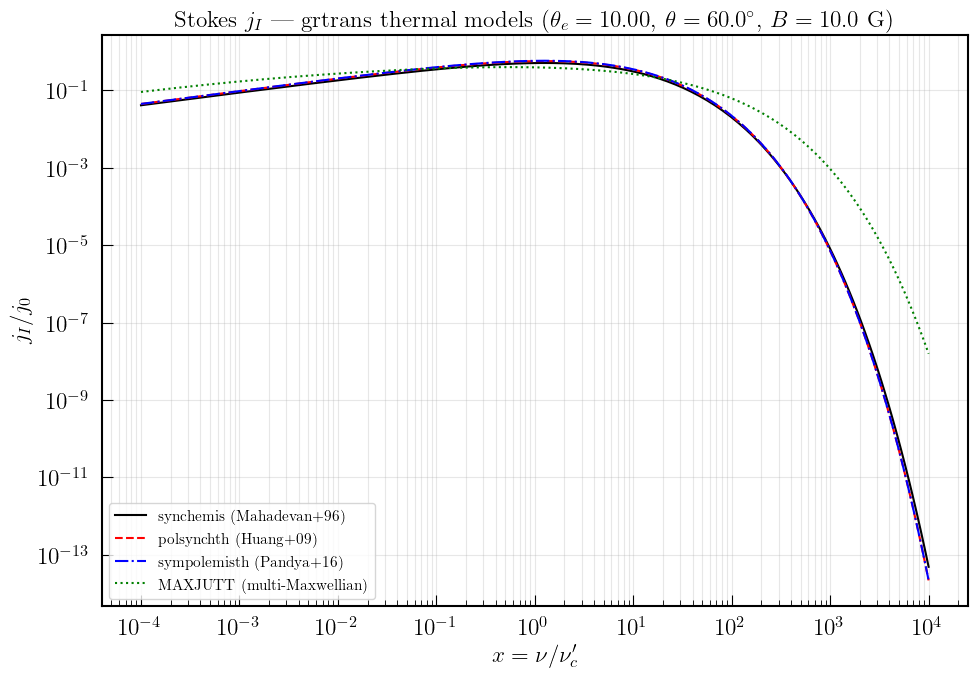

In [24]:
fig, ax = plt.subplots(figsize=(10, 7))

styles = {'synchemis (Mahadevan+96)':   dict(color='k', ls='-'),
          'polsynchth (Huang+09)':      dict(color='r', ls='--'),
          'sympolemisth (Pandya+16)':   dict(color='b', ls='-.'),
          'MAXJUTT (multi-Maxwellian)': dict(color='g', ls=':')}

for name, res in norm_models.items():
    ax.loglog(xs, res['jI'], label=name, **styles[name])

ax.set_xlabel(r"$x = \nu / \nu_c'$")
ax.set_ylabel(r'$j_I / j_0$')
ax.set_title(r'Stokes $j_I$ — grtrans thermal models '
             r'($\theta_e=%.2f$, $\theta=%.1f^\circ$, $B=%.1f$ G)'
             % (theta_e, np.degrees(theta_B), B))
ax.legend(loc='lower left', fontsize=11)
ax.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.show()

#### Plot 2: $\theta_e$ dependence in the mildly relativistic regime

$j_I$ from `polsynchth` for $\theta_e \in [0.1, 10]$, plotted against $x = \nu/\nu_c'(\theta_e)$ (each curve uses its own $\nu_c'$). This is the regime where the ultrarelativistic fits start to break down near the low-frequency end.

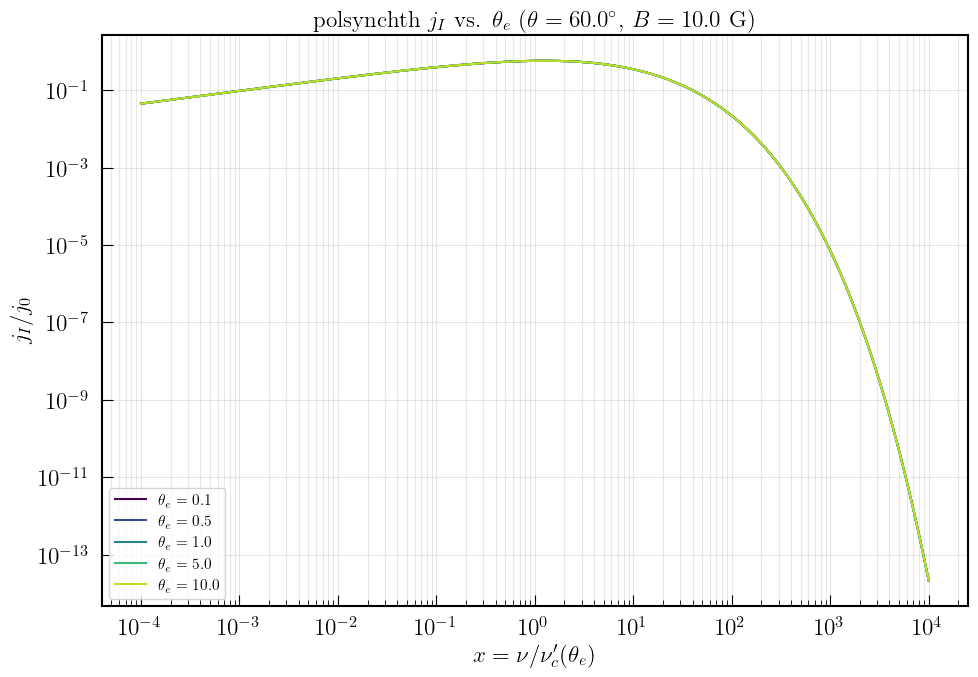

In [25]:
theta_e_scan = [0.1, 0.5, 1.0, 5.0, 10.0]
colors = plt.cm.viridis(np.linspace(0, 0.9, len(theta_e_scan)))

fig, ax = plt.subplots(figsize=(10, 7))

for te, col in zip(theta_e_scan, colors):
    T_loc = te*m_e*c**2/k_B
    ncp_loc = get_nuc_prime(B, te, theta_B)
    nus_loc = xs*ncp_loc
    with np.errstate(all='ignore'):
        res_loc = polsynchth(nus_loc, n_e, B, T_loc, theta_B)
    ax.loglog(xs, normalize_jnu(res_loc['jI'], B, n_e),
              color=col, label=r'$\theta_e = %.1f$' % te)

ax.set_xlabel(r"$x = \nu / \nu_c'(\theta_e)$")
ax.set_ylabel(r'$j_I / j_0$')
ax.set_title(r'polsynchth $j_I$ vs. $\theta_e$ '
             r'($\theta=%.1f^\circ$, $B=%.1f$ G)' % (np.degrees(theta_B), B))
ax.legend(loc='lower left', fontsize=11)
ax.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.show()

#### Summary Statistics

Peak locations and relative differences between the models at the fiducial parameters.

In [26]:
print("=" * 66)
print(f"Model summary at theta_e = {theta_e}, theta = {np.degrees(theta_B):.1f} deg, B = {B} G")
print("=" * 66)
print(f"{'model':<28} {'peak x = nu/nu_c':>18} {'peak j_I/j0':>18}")
print("-" * 66)
for name, res in norm_models.items():
    jI = res['jI']
    imax = np.nanargmax(jI)
    print(f"{name:<28} {xs[imax]:>18.4f} {jI[imax]:>18.4e}")
print("=" * 66)

# Relative difference between the two polarized fits for Stokes I
ref = norm_models['polsynchth (Huang+09)']['jI']
cmp = norm_models['sympolemisth (Pandya+16)']['jI']
mask = np.abs(ref) > 1e-30
rel = np.full_like(ref, np.nan)
rel[mask] = np.abs((ref[mask] - cmp[mask])/ref[mask])
print(f"\n|polsynchth - sympolemisth|/polsynchth for j_I:")
print(f"  median = {np.nanmedian(rel):.4f}   max = {np.nanmax(rel):.4f}")

Model summary at theta_e = 10, theta = 60.0 deg, B = 10.0 G
model                          peak x = nu/nu_c        peak j_I/j0
------------------------------------------------------------------
synchemis (Mahadevan+96)                 1.2604         5.1066e-01
polsynchth (Huang+09)                    1.2604         5.7181e-01
sympolemisth (Pandya+16)                 1.2604         5.8316e-01
MAXJUTT (multi-Maxwellian)               0.5479         3.9952e-01

|polsynchth - sympolemisth|/polsynchth for j_I:
  median = 0.0115   max = 0.0199


#### Plotting over $\theta_e$ (Plot 1)

In [31]:
def plot_stokesI(theta_e, B=10.0, theta_B=np.pi/3., n_e=1.0,
                 x_min=1e-4, x_max=1e4, num_pts=200,
                 delta=2., weights=np.array([1., 2., 3., 5., 7., 11., 13., 17.]),
                 figsize=(10, 7), ax=None, show=True):
    """Reproduce the Plot 1 figure (normalized Stokes j_I vs. x = nu/nu_c'
    for all four grtrans thermal models) for a given dimensionless electron
    temperature theta_e.

    Parameters
    ----------
    theta_e : float
        Dimensionless electron temperature k_B T_e / (m_e c^2).
    B : float
        Magnetic field strength [Gauss].
    theta_B : float
        Angle between B-field and line of sight [rad].
    n_e : float
        Electron number density [cm^-3].
    x_min, x_max : float
        Frequency-grid limits in units of nu_c'.
    num_pts : int
        Number of log-spaced frequency points.
    delta, weights : MAXJUTT decomposition parameters.
    figsize : tuple
        Figure size (only used when creating a new figure).
    ax : matplotlib Axes, optional
        Draw into an existing axes instead of creating a new figure.
    show : bool
        Call plt.show() at the end (only when creating a new figure).

    Returns
    -------
    fig, ax : the matplotlib figure and axes.
    results : dict
        {model name: {'xs', 'jI_norm'}} for further analysis.
    """
    T_e = theta_e*m_e*c**2/k_B
    ncp = get_nuc_prime(B, theta_e, theta_B)
    xs  = np.logspace(np.log10(x_min), np.log10(x_max), num_pts)
    nus = xs*ncp

    with np.errstate(all='ignore'):
        model_res = {
            'synchemis (Mahadevan+96)':   synchemis(nus, n_e, B, T_e),
            'polsynchth (Huang+09)':      polsynchth(nus, n_e, B, T_e, theta_B),
            'sympolemisth (Pandya+16)':   sympolemisth(nus, n_e, B, T_e, theta_B),
            'MAXJUTT (multi-Maxwellian)': maxjutt(nus, n_e, B, T_e, theta_B,
                                                  delta=delta, weights=weights),
        }

    styles = {'synchemis (Mahadevan+96)':   dict(color='k', ls='-'),
              'polsynchth (Huang+09)':      dict(color='r', ls='--'),
              'sympolemisth (Pandya+16)':   dict(color='b', ls='-.'),
              'MAXJUTT (multi-Maxwellian)': dict(color='g', ls=':')}

    created = ax is None
    if created:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.figure

    results = {}
    for name, res in model_res.items():
        jI_norm = normalize_jnu(res['jI'], B, n_e)
        results[name] = {'xs': xs, 'jI_norm': jI_norm}
        ax.loglog(xs, jI_norm, label=name, **styles[name])

    ax.set_xlabel(r"$x = \nu / \nu_c'$")
    ax.set_ylabel(r'$j_I / j_0$')
    ax.set_title(r'Stokes $j_I$ — grtrans thermal models '
                 r'($\theta_e=%.2e$, $\theta=%.1f^\circ$, $B=%.1f$ G)'
                 % (theta_e, np.degrees(theta_B), B))
    ax.legend(loc='lower left', fontsize=11)
    ax.grid(True, which='both', alpha=0.3)

    if created:
        plt.tight_layout()
        if show:
            plt.show()
    return fig, ax, results


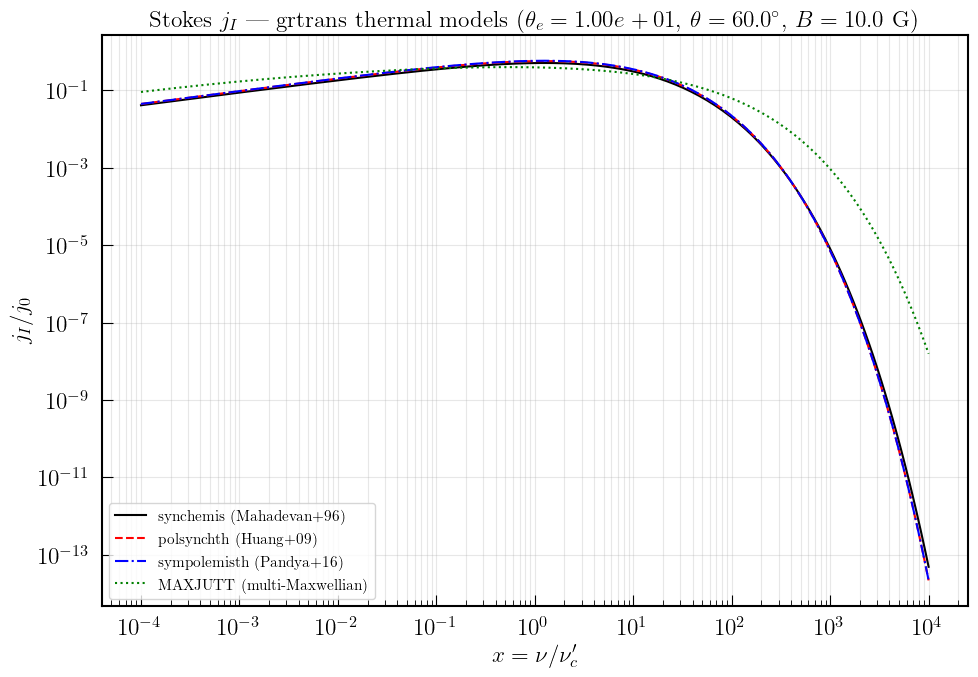

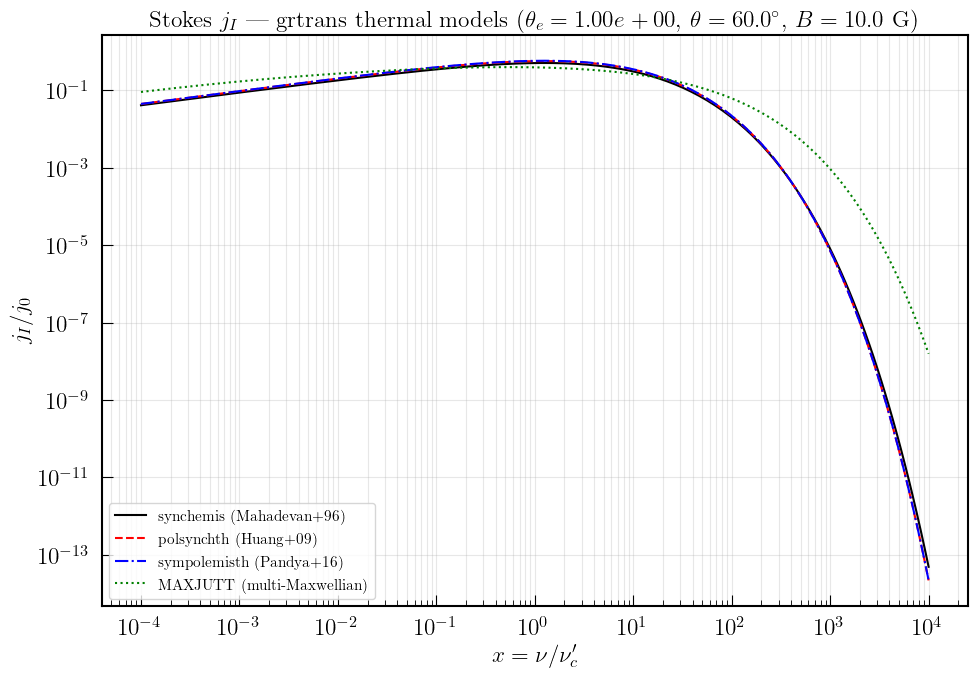

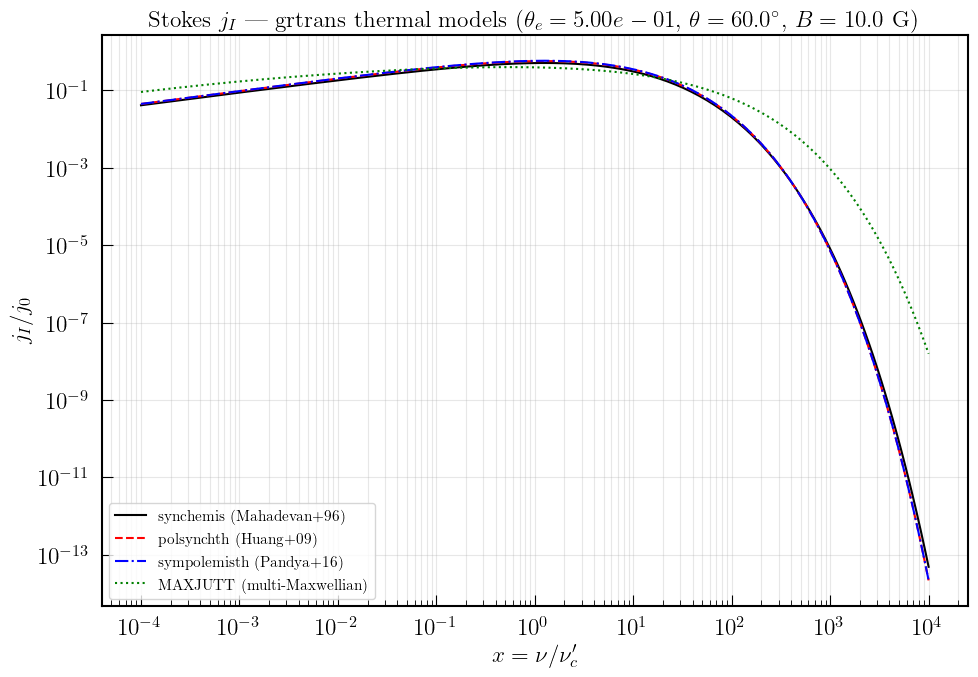

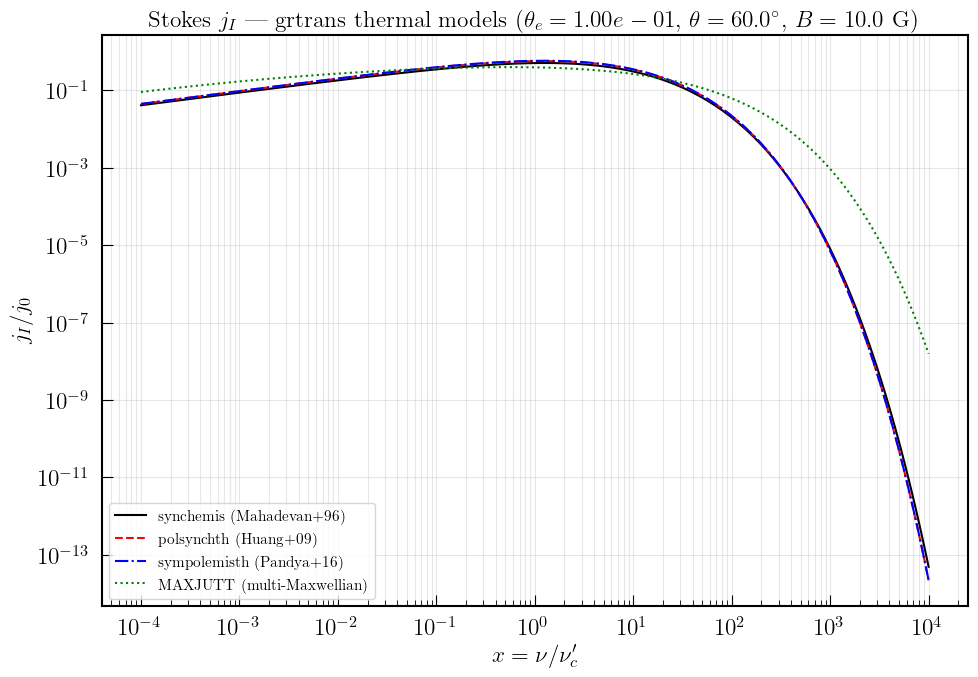

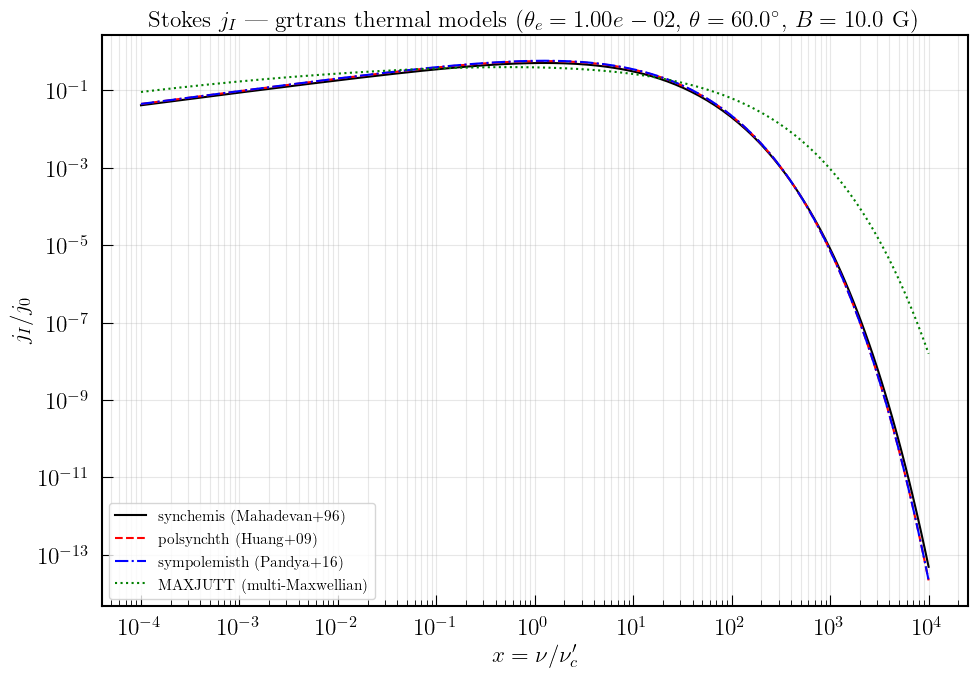

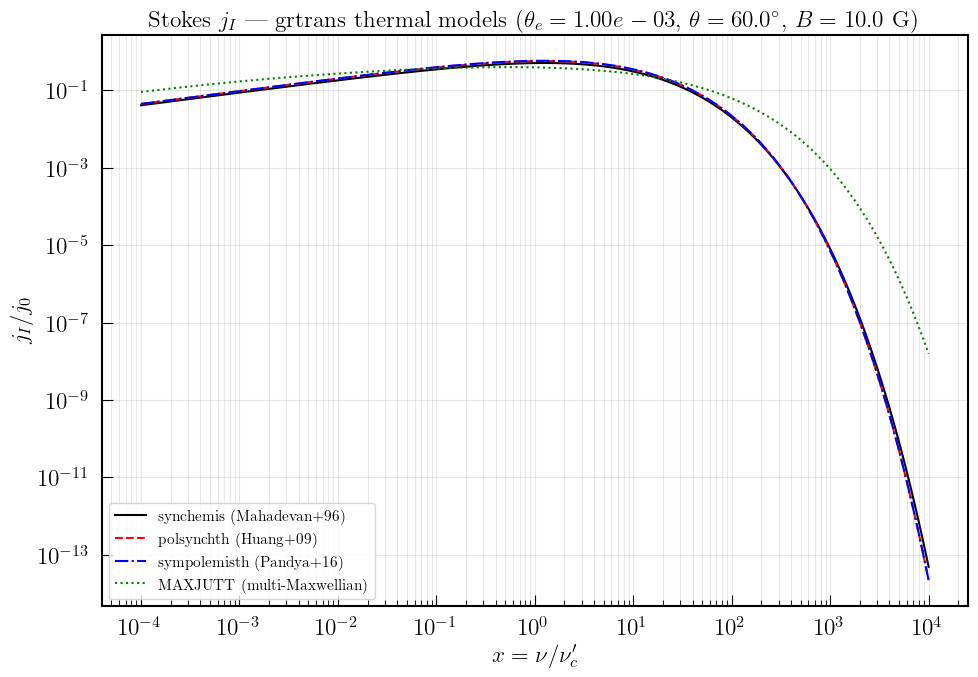

In [32]:
# Example: make the attached plot for theta_e = 10
fig, ax, results_theta10 = plot_stokesI(theta_e=10.)
fig, ax, results_theta10 = plot_stokesI(theta_e=1.)
fig, ax, results_theta10 = plot_stokesI(theta_e=.5)
fig, ax, results_theta10 = plot_stokesI(theta_e=.1)
fig, ax, results_theta10 = plot_stokesI(theta_e=.01)
fig, ax, results_theta10 = plot_stokesI(theta_e=.001)